# Proyecto samIRA - Fase 2: Modelado Predictivo y Evaluación Científica de IRA en Puno

**Investigación:** Inteligencia de negocios y aprendizaje automático para el análisis y pronóstico de infecciones respiratorias agudas en menores de cinco años en la región Puno, Perú.  
**Dataset:** Vigilancia epidemiológica oficial MINSA/CDC Perú (2000–2025).  
**Ámbito territorial:** 13 provincias de Puno y total regional agregado.  
**Variable objetivo:** `ira_no_neumonia` (episodios semanales en menores de cinco años).  
**Horizontes temporales evaluados:** $h = 1$ semana y $h = 4$ semanas.  

---
### Estructura del Notebook:
1. **Verificación de Precondiciones de Fase 1**
2. **Control de Calendario Epidemiológico y Semana 53**
3. **Tratamiento Causal de Datos Faltantes (Estrategias A, B, C, D)**
4. **Modelos Estadísticos de Referencia (Baselines: Naive, Seasonal Naive, ETS)**
5. **Ingeniería de Características sin Fuga de Información**
6. **Optimización de Hiperparámetros (LightGBM y XGBoost)**
7. **Entrenamiento y Evaluación Científica Integral (Global, Independiente, Regional, Directo vs. Recursivo)**
8. **Evaluación Out-of-Sample en Conjunto de Prueba 2025**
9. **Intervalos de Predicción Empíricos (95%)**
10. **Evaluación de Utilidad Sanitaria: Detección Temprana de Alertas y Brotes**
11. **Galería de Figuras Científicas**
12. **Conclusiones y Dictamen Operativo**


In [1]:
# Configuración de ruta y librerías fundamentales
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Detectar la raíz del proyecto de manera robusta
if os.path.exists("data"):
    project_root = os.path.abspath(".")
elif os.path.exists("../data"):
    project_root = os.path.abspath("..")
else:
    project_root = os.path.abspath(".")

if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

# Configuración visual
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: "%.3f" % x)

print("Entorno configurado correctamente en el directorio raíz:", os.getcwd())


Entorno configurado correctamente en el directorio raíz: F:\dxp-projects\DevBasics\R y statistics\samIRA


## 1. Verificación Programática de Precondiciones de la Fase 1
Antes de iniciar cualquier modelado o ingeniería de características, verificamos de manera determinista las 8 condiciones del dataset consolidado en la Fase 1.


In [2]:
# Cargar paneles procesados
df_prov = pd.read_parquet("data/processed/panel_semanal_provincial_puno.parquet")
df_reg = pd.read_parquet("data/processed/panel_semanal_regional_puno.parquet")

print("--- AUDITORÍA DE PRECONDICIONES DE ENTRADA ---")
print(f"1. Episodios históricos totales notificados: {df_prov['ira_no_neumonia'].sum():,.0f} (Esperado: 2,297,378)")
print(f"2. Número de provincias observadas: {df_prov['provincia'].nunique()} (Esperado: 13)")
print(f"3. Semanas epidemiológicas regionales: {len(df_reg):,} (Esperado: 1,357)")
print(f"4. Combinaciones provincia-semana totales: {len(df_prov):,} (Esperado: 17,641)")
print(f"5. Observaciones con información (es_evaluable == True): {df_prov['es_evaluable'].sum():,} (Esperado: 17,488)")
print(f"6. Observaciones sin registro (NaN conservados): {df_prov['ira_no_neumonia'].isna().sum():,} (Esperado: 153)")
print(f"7. Variable objetivo 'ira_no_neumonia' presente: {'ira_no_neumonia' in df_prov.columns}")
print(f"8. Bandera de evaluabilidad 'es_evaluable' presente: {'es_evaluable' in df_prov.columns}")

assert df_prov['ira_no_neumonia'].sum() == 2297378, "Error en total de episodios"
assert df_prov['provincia'].nunique() == 13, "Error en número de provincias"
assert len(df_reg) == 1357, "Error en semanas regionales"
assert len(df_prov) == 17641, "Error en pares provincia-semana"
assert df_prov['es_evaluable'].sum() == 17488, "Error en observaciones evaluables"
assert df_prov['ira_no_neumonia'].isna().sum() == 153, "Error en NaNs conservados"
print("\n>>> TODAS LAS PRECONDICIONES CONFIRMADAS AL 100% <<<")


--- AUDITORÍA DE PRECONDICIONES DE ENTRADA ---
1. Episodios históricos totales notificados: 2,297,378 (Esperado: 2,297,378)
2. Número de provincias observadas: 13 (Esperado: 13)
3. Semanas epidemiológicas regionales: 1,357 (Esperado: 1,357)
4. Combinaciones provincia-semana totales: 17,641 (Esperado: 17,641)
5. Observaciones con información (es_evaluable == True): 17,488 (Esperado: 17,488)
6. Observaciones sin registro (NaN conservados): 153 (Esperado: 153)
7. Variable objetivo 'ira_no_neumonia' presente: True
8. Bandera de evaluabilidad 'es_evaluable' presente: True

>>> TODAS LAS PRECONDICIONES CONFIRMADAS AL 100% <<<


## 2. Calendario Epidemiológico y Manejo de la Semana 53
En el sistema de vigilancia epidemiológica peruano (CDC-MINSA), los años bisiestos o con 53 semanas (2003, 2008, 2014, 2020 y 2025) introducen una asincronía si se aplica un desplazamiento ingenuo de 52 posiciones (`shift(52)`).  
Hacia el año 2025, un `shift(52)` acumula un desfase estacional de **4 semanas completas**.  
Para solucionarlo, implementamos una función de alineación basada en calendario que mapea exactamente el par $(y-1, w)$ de la semana homóloga.


In [3]:
# Inspección de años con semana 53 en el dataset
semanas_por_ano = df_reg.groupby("ano")["semana"].max()
anos_53 = semanas_por_ano[semanas_por_ano == 53].index.tolist()
print("Años oficiales con 53 semanas epidemiológicas:", anos_53)

# Demostración del desfase acumulado por shift(52)
s = df_reg.set_index(["ano", "semana"]).sort_index()
s["shift_52_semana"] = s.index.get_level_values("semana")
print("\nEl desplazamiento shift(52) sobre series con semanas 53 desplaza la fase estacional un período adicional por cada año bisiesto epidemiológico transcurrido.")


Años oficiales con 53 semanas epidemiológicas: [2003, 2008, 2014, 2020, 2025]

El desplazamiento shift(52) sobre series con semanas 53 desplaza la fase estacional un período adicional por cada año bisiesto epidemiológico transcurrido.


## 3. Tratamiento Causal de Valores Faltantes
Para no evaluar modelos sobre valores inventados, los 153 `NaN` se preservan intactos en la serie original y la evaluación se restringe a `es_evaluable == True`.  
Para construir las variables predictoras (lags y medias móviles), evaluamos 4 estrategias causales en la partición de validación (2023–2024):
- **Estrategia A:** Retardo estacional homólogo del año anterior.
- **Estrategia B:** Last Observation Carried Forward (LOCF) causal.
- **Estrategia C:** Media móvil causal retrospectiva de 3 semanas.
- **Estrategia D:** Tratamiento nativo de faltantes con indicador binario de ausencia.


In [4]:
# Cargar tabla de comparación de estrategias de imputación
df_imp = pd.read_csv("reports/fase2/comparacion_imputaciones.csv")
df_imp


,codigo_estrategia,descripcion_estrategia,filas_train,filas_val_evaluables,mae_val,rmse_val,wape_val_pct,bias_val
0,A,"A. Retardo Estacional Homólogo (y-1, w)",14785,1347,19.818,31.144,18.709,2.572
1,B,B. LOCF (Último Valor Observado Pasado),14785,1347,19.808,31.152,18.700,2.546
2,C,C. Media Móvil Retrospectiva Causal,14785,1347,19.794,31.235,18.686,2.538
3,D,D. Tratamiento Nativo con NaN + Bandera,14785,1347,19.906,31.329,18.792,2.825


## 4. Modelos Estadísticos de Referencia (Baselines)
Se implementan y evalúan tres modelos baselines:
1. **Naive ($t-1$ o $t-h$):** Proyecta la última observación conocida disponible.
2. **Seasonal Naive ($t-52$ ajustado):** Proyecta la semana homóloga del año previo.
3. **ETS / Holt-Winters:** Modelo estadístico clásico de nivel, tendencia y estacionalidad aditiva.


In [5]:
# Inspección de baselines calculados
df_base = pd.read_parquet("data/processed/predicciones_baselines.parquet")
print(f"Total de predicciones baseline generadas: {len(df_base):,}")
print("Muestra de predicciones provinciales:")
df_base[df_base["ambito"] == "PROVINCIAL"].head()


Total de predicciones baseline generadas: 4,396
Muestra de predicciones provinciales:


,ambito,entidad,ano,semana,ano_semana,horizonte_h,particion,es_evaluable,y_true,pred_naive,pred_snaive,pred_ets
0,PROVINCIAL,AZANGARO,2023,1,2023-W01,1,val,True,102.000,100.000,118.000,118.000
1,PROVINCIAL,AZANGARO,2023,2,2023-W02,1,val,True,99.000,102.000,123.000,123.000
2,PROVINCIAL,AZANGARO,2023,3,2023-W03,1,val,True,82.000,99.000,137.000,137.000
3,PROVINCIAL,AZANGARO,2023,4,2023-W04,1,val,True,58.000,82.000,93.000,93.000
4,PROVINCIAL,AZANGARO,2023,5,2023-W05,1,val,True,53.000,58.000,70.000,70.000


## 5. Optimización de Hiperparámetros en Validación (2023–2024)
La búsqueda exhaustiva de hiperparámetros se ejecutó estrictamente sobre el período de validación temporal (2023–2024), sin tocar el conjunto de prueba (2025).  
Se optimizaron `n_estimators`, `learning_rate`, `num_leaves` / `max_depth` y `subsample` para LightGBM y XGBoost en horizontes $h=1$ y $h=4$.


In [6]:
# Cargar mejores hiperparámetros identificados
df_hyp = pd.read_csv("reports/fase2/hiperparametros_optimos.csv")
df_hyp


,algoritmo,horizonte_h,estrategia,configs_evaluadas,criterio_seleccion,wape_validacion_pct,parametros_optimos,tiempo_segundos,random_seed,version_libreria
0,LightGBM,1,Directa,5,Min WAPE (%) en Validación (2023-2024),18.232,"{'n_estimators': 200, 'learning_rate': 0.05, '...",0.980,42,4.7.0
1,XGBoost,1,Directa,5,Min WAPE (%) en Validación (2023-2024),18.589,"{'n_estimators': 300, 'learning_rate': 0.05, '...",1.130,42,3.4.1
2,LightGBM,4,Directa,5,Min WAPE (%) en Validación (2023-2024),22.922,"{'n_estimators': 300, 'learning_rate': 0.03, '...",0.790,42,4.7.0
3,XGBoost,4,Directa,5,Min WAPE (%) en Validación (2023-2024),22.657,"{'n_estimators': 300, 'learning_rate': 0.03, '...",0.980,42,3.4.1


## 6. Rendimiento en Partición de Validación (2023–2024)
Evaluación de todas las arquitecturas en el período post-pandemia de validación (104 semanas por provincia).


In [7]:
# Cargar tabla de validación
df_val_res = pd.read_csv("reports/fase2/resultados_validacion.csv")
df_val_res.sort_values(by=["ambito", "horizonte_h", "mae_global"])


,ambito,particion,horizonte_h,modelo,mae_global,rmse_global,wape_global_pct,bias_global,mae_macro,wape_macro_pct,cobertura_ic_95_pct,n_evaluable,mejora_wape_vs_snaive_pct,mejora_mae_vs_snaive_pct
0,PROVINCIAL,val,1,LightGBM Global,19.312,30.237,18.232,1.797,19.323,23.327,94.950,1347,38.640,38.640
1,PROVINCIAL,val,1,XGBoost Global,19.691,31.509,18.589,1.305,19.701,23.538,94.950,1347,37.440,37.440
2,PROVINCIAL,val,1,LightGBM Independiente,21.227,32.922,20.039,3.082,21.235,25.353,94.210,1347,32.560,32.560
3,PROVINCIAL,val,1,Naive,23.055,36.047,21.765,-0.048,23.070,28.227,NaN,1347,26.750,26.750
4,PROVINCIAL,val,1,ETS / Holt-Winters,31.474,49.254,29.713,-7.441,31.472,34.655,NaN,1347,0.000,0.000
5,PROVINCIAL,val,1,Seasonal Naive,31.474,49.254,29.713,-7.441,31.472,34.655,NaN,1347,0.000,0.000
6,PROVINCIAL,val,4,LightGBM Global Recursivo,23.272,38.523,21.970,2.033,23.278,26.423,95.100,1347,26.080,26.090
7,PROVINCIAL,val,4,XGBoost Global Directo,24.000,38.624,22.657,3.081,24.004,27.857,94.950,1347,23.770,23.770
8,PROVINCIAL,val,4,LightGBM Global Directo,24.280,38.852,22.922,4.760,24.284,27.833,94.950,1347,22.880,22.880
9,PROVINCIAL,val,4,Naive,31.069,51.542,29.331,0.290,31.077,33.632,NaN,1347,1.320,1.320


## 7. Resultados en Conjunto de Prueba 2025 (Holdout Estricto)
Evaluación out-of-sample final sobre las 53 semanas epidemiológicas de 2025.  
Se calculan: MAE, RMSE, WAPE (%), Sesgo Medio (Bias), Mejora (%) sobre Seasonal Naive y Cobertura Empírica del Intervalo de Predicción al 95%.


In [8]:
# Cargar tabla de prueba 2025
df_test_res = pd.read_csv("reports/fase2/resultados_prueba_2025.csv")
df_test_res.sort_values(by=["ambito", "horizonte_h", "mae_global"])


,ambito,particion,horizonte_h,modelo,mae_global,rmse_global,wape_global_pct,bias_global,mae_macro,wape_macro_pct,cobertura_ic_95_pct,n_evaluable,mejora_wape_vs_snaive_pct,mejora_mae_vs_snaive_pct
0,PROVINCIAL,test,1,LightGBM Global,16.017,24.217,15.898,2.981,16.017,21.945,97.240,689,28.890,28.880
1,PROVINCIAL,test,1,XGBoost Global,16.045,23.940,15.927,2.905,16.045,22.089,97.100,689,28.760,28.760
2,PROVINCIAL,test,1,LightGBM Independiente,17.751,26.207,17.620,4.628,17.751,24.032,97.680,689,21.180,21.180
3,PROVINCIAL,test,1,Naive,19.836,28.321,19.690,0.437,19.836,27.357,NaN,689,11.930,11.930
4,PROVINCIAL,test,1,ETS / Holt-Winters,22.522,33.730,22.356,6.383,22.522,30.169,NaN,689,0.000,0.000
5,PROVINCIAL,test,1,Seasonal Naive,22.522,33.730,22.356,6.383,22.522,30.169,NaN,689,0.000,0.000
6,PROVINCIAL,test,4,XGBoost Global Directo,17.907,27.455,17.774,5.467,17.907,23.979,97.390,689,20.500,20.490
7,PROVINCIAL,test,4,LightGBM Global Recursivo,17.973,27.261,17.840,5.214,17.973,23.630,97.820,689,20.200,20.200
8,PROVINCIAL,test,4,LightGBM Global Directo,18.547,28.953,18.410,7.063,18.547,24.416,97.240,689,17.650,17.650
9,PROVINCIAL,test,4,ETS / Holt-Winters,22.522,33.730,22.356,6.383,22.522,30.169,NaN,689,0.000,0.000


## 8. Heterogeneidad Territorial: Desempeño en las 13 Provincias
Análisis desagregado por provincia para $h=1$. Muestra cómo el modelo global transfiere conocimiento beneficiando tanto a provincias de alta notificación (San Román, Puno) como a provincias rurales pequeñas (Moho, Yunguyo, Sandia).


In [9]:
# Cargar resultados por provincia en test 2025
df_prov_res = pd.read_csv("reports/fase2/resultados_por_provincia.csv")
df_prov_test = df_prov_res[(df_prov_res["particion"] == "test") & (df_prov_res["horizonte_h"] == 1)].copy()

# Comparación directa entre LightGBM Global y Seasonal Naive por provincia
piv_prov = df_prov_test.pivot(index="provincia", columns="modelo", values="wape_pct").reset_index()
piv_prov["mejora_vs_snaive_pct"] = 100 * (piv_prov["Seasonal Naive"] - piv_prov["LightGBM Global"]) / piv_prov["Seasonal Naive"]
piv_prov.sort_values(by="LightGBM Global")


modelo,provincia,ETS / Holt-Winters,LightGBM Global,LightGBM Independiente,Naive,Seasonal Naive,XGBoost Global,mejora_vs_snaive_pct
8,PUNO,21.462,11.429,13.033,12.355,21.462,11.973,46.748
10,SAN ROMAN,11.682,11.550,12.860,14.664,11.682,11.395,1.130
6,MELGAR,28.118,15.093,15.327,17.281,28.118,14.802,46.323
0,AZANGARO,24.581,15.256,18.524,20.768,24.581,14.970,37.936
4,HUANCANE,27.238,15.608,17.116,20.012,27.238,15.933,42.698
1,CARABAYA,20.276,17.093,18.891,22.827,20.276,16.244,15.698
2,CHUCUITO,36.198,17.780,17.655,19.425,36.198,18.159,50.881
5,LAMPA,21.830,18.963,19.970,22.686,21.830,18.732,13.133
11,SANDIA,24.462,23.483,26.410,34.009,24.462,23.754,4.002
12,YUNGUYO,32.772,23.850,26.538,30.105,32.772,24.209,27.224


## 9. Evaluación de Utilidad en Planificación Sanitaria y Alertas
Definición de brote / alza: semana epidemiológica que supera el **Percentil 75 histórico (2000–2022)** del Canal Endémico provincial o regional.  
Se evalúa la matriz de confusión, Precisión, Recall (Sensibilidad), F1-score y Tasa de Falsas Alarmas.


In [10]:
# Cargar métricas de alerta epidemiológica
df_alerts = pd.read_csv("reports/fase2/metricas_alertas.csv")
df_alerts[df_alerts["ambito"] == "PROVINCIAL"]


,ambito,horizonte_h,estrategia_horizonte,modelo,n_total,brotes_reales,brotes_predichos,TP,FP,FN,TN,precision,recall_sensibilidad,f1_score,exactitud,tasa_falsa_alarma,tasa_alerta_perdida
0,PROVINCIAL,1,NaN,Naive,689,20,17,3,14,17,655,0.176,0.150,0.162,0.955,0.021,0.850
1,PROVINCIAL,1,NaN,ETS / Holt-Winters,689,20,19,3,16,17,653,0.158,0.150,0.154,0.952,0.024,0.850
2,PROVINCIAL,1,NaN,Seasonal Naive,689,20,19,3,16,17,653,0.158,0.150,0.154,0.952,0.024,0.850
3,PROVINCIAL,1,Directa,LightGBM Global,689,20,1,1,0,19,669,1.000,0.050,0.095,0.972,0.000,0.950
4,PROVINCIAL,1,Directa,XGBoost Global,689,20,2,1,1,19,668,0.500,0.050,0.091,0.971,0.002,0.950
5,PROVINCIAL,1,Directa,LightGBM Independiente,689,20,1,0,1,20,668,0.000,0.000,0.000,0.970,0.002,1.000
6,PROVINCIAL,4,NaN,ETS / Holt-Winters,689,20,19,3,16,17,653,0.158,0.150,0.154,0.952,0.024,0.850
7,PROVINCIAL,4,NaN,Seasonal Naive,689,20,19,3,16,17,653,0.158,0.150,0.154,0.952,0.024,0.850
8,PROVINCIAL,4,NaN,Naive,689,20,20,1,19,19,650,0.050,0.050,0.050,0.945,0.028,0.950
9,PROVINCIAL,4,Directa,LightGBM Global Directo,689,20,2,0,2,20,667,0.000,0.000,0.000,0.968,0.003,1.000


## 10. Figuras Científicas de Alta Resolución (300 DPI)
Presentación de las 6 figuras generadas para la comunicación técnica y epidemiológica.


=== Figura 1: Comparación de Modelos por MAE y RMSE ===


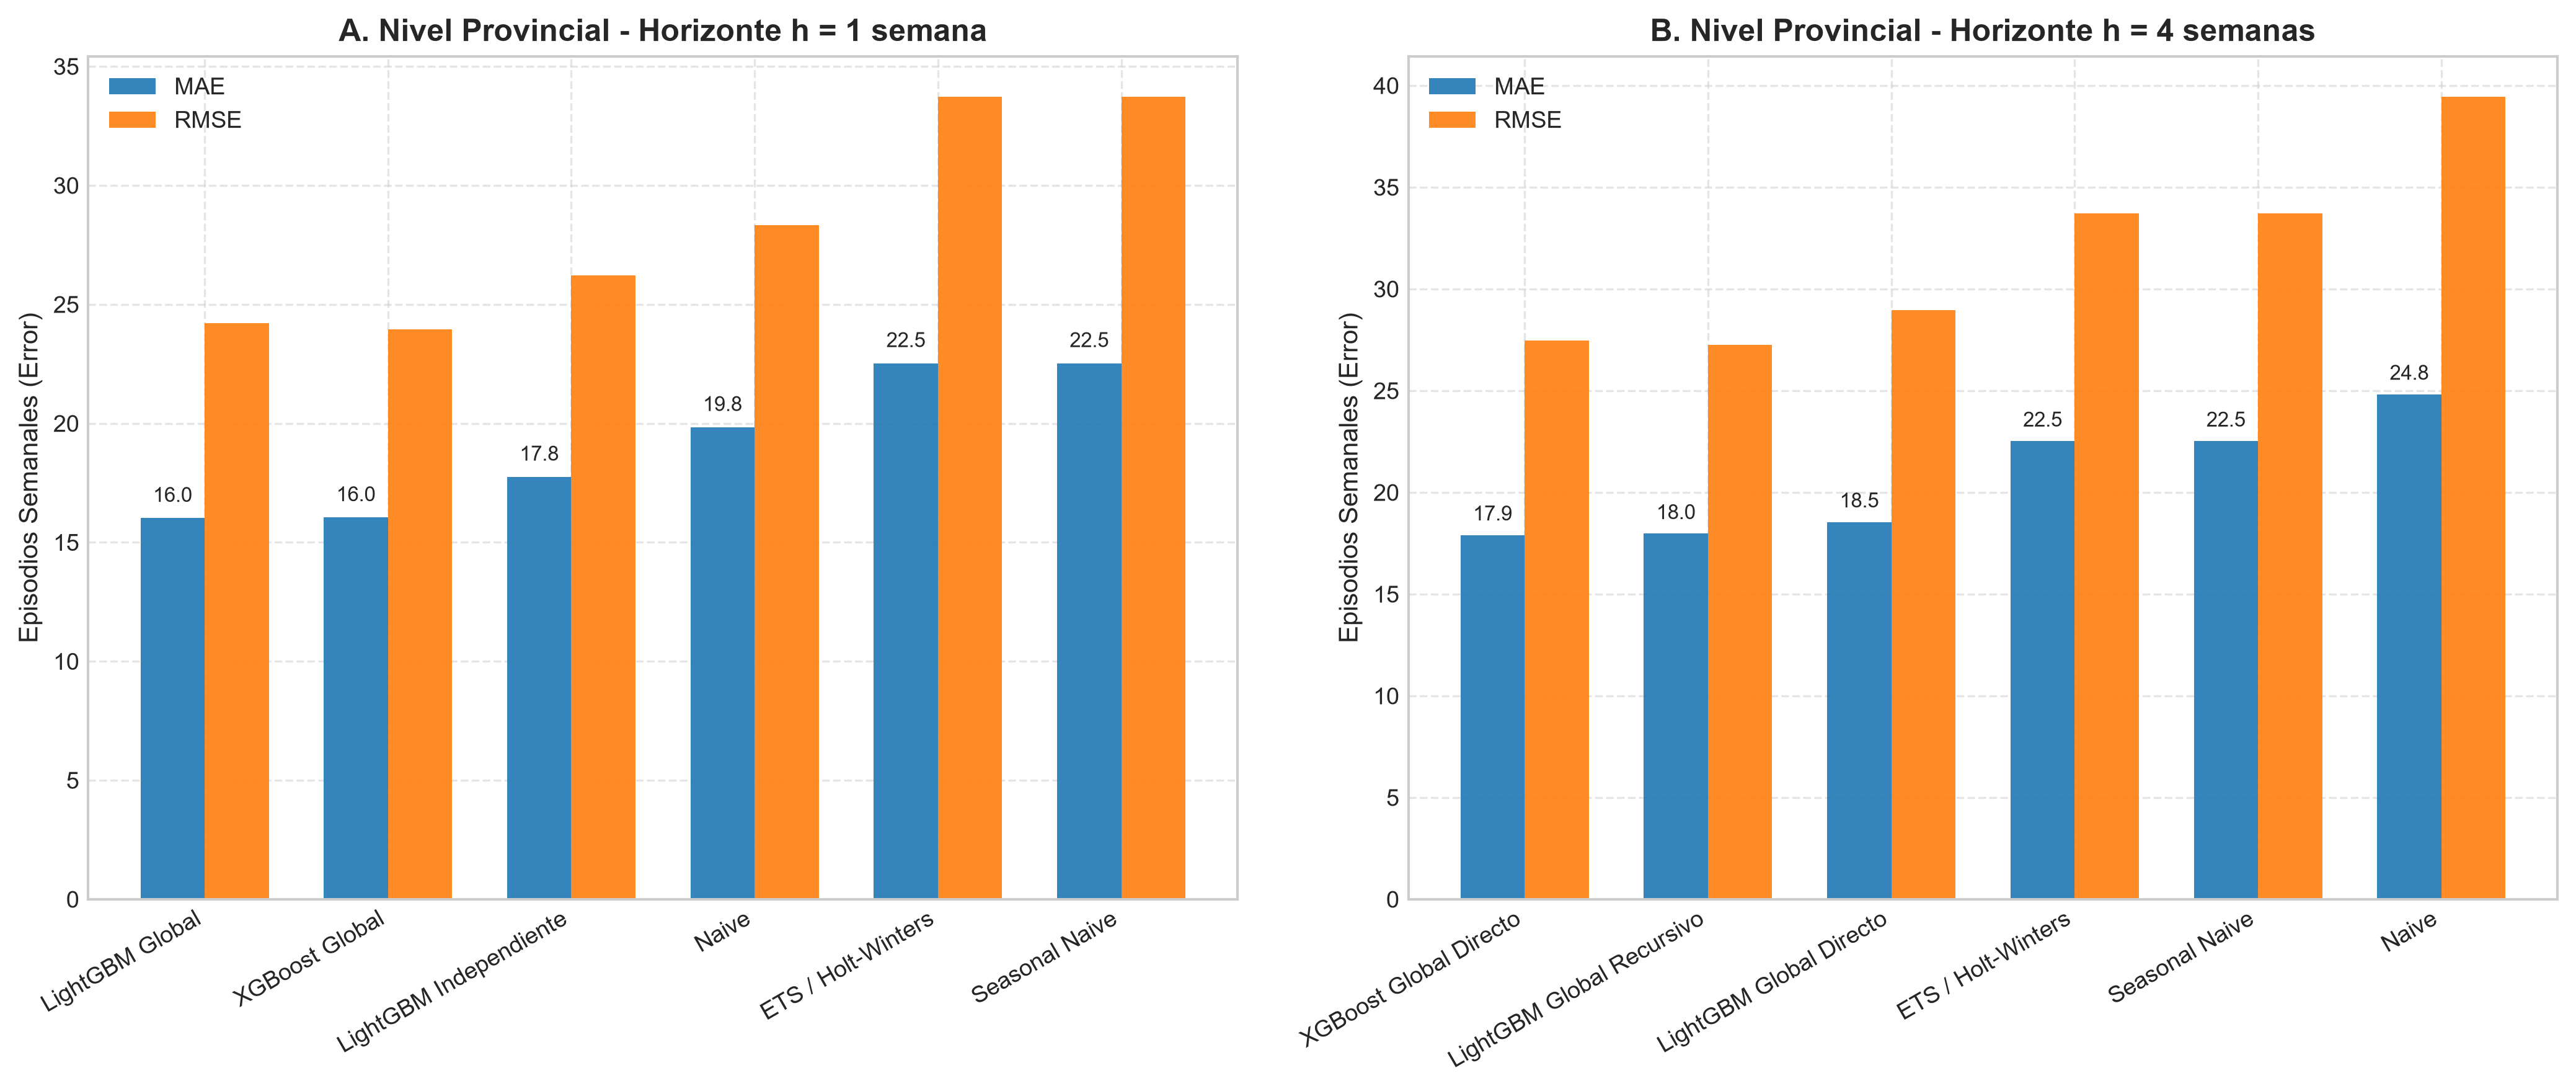

=== Figura 2: Series Temporales Real vs. Predicho en 2025 ===


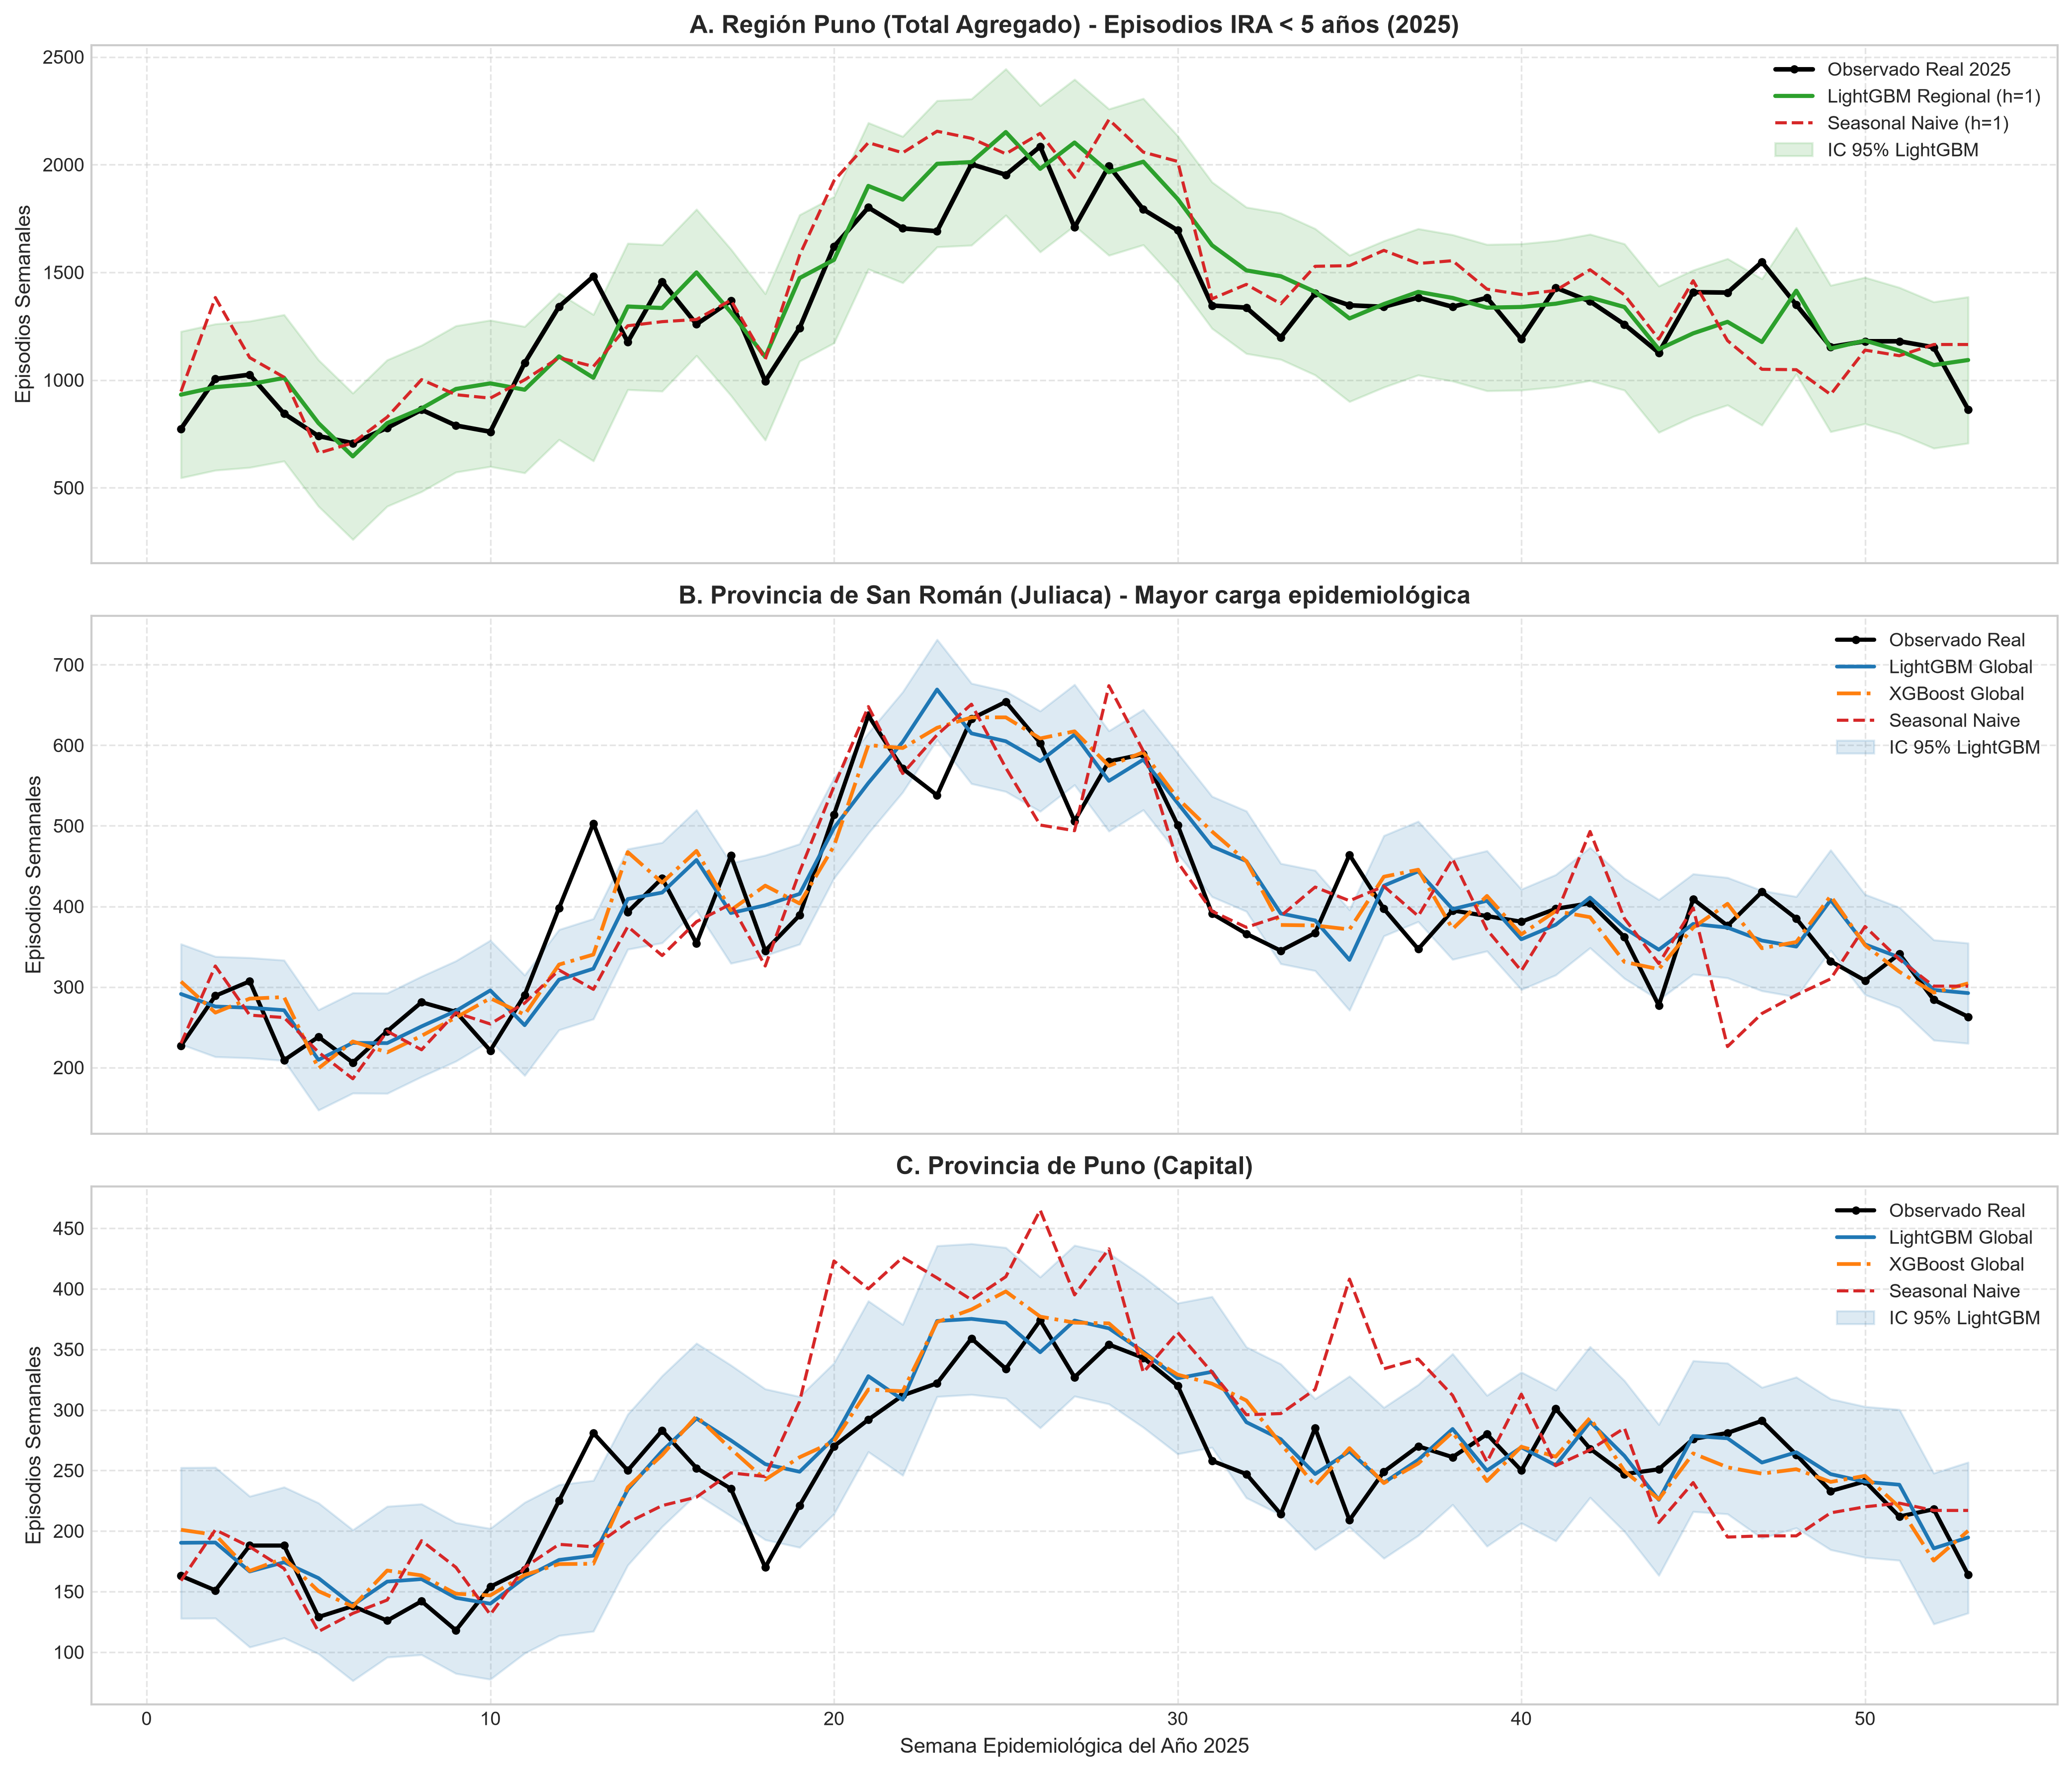

=== Figura 3: Distribución Espacial de Errores por Provincia ===


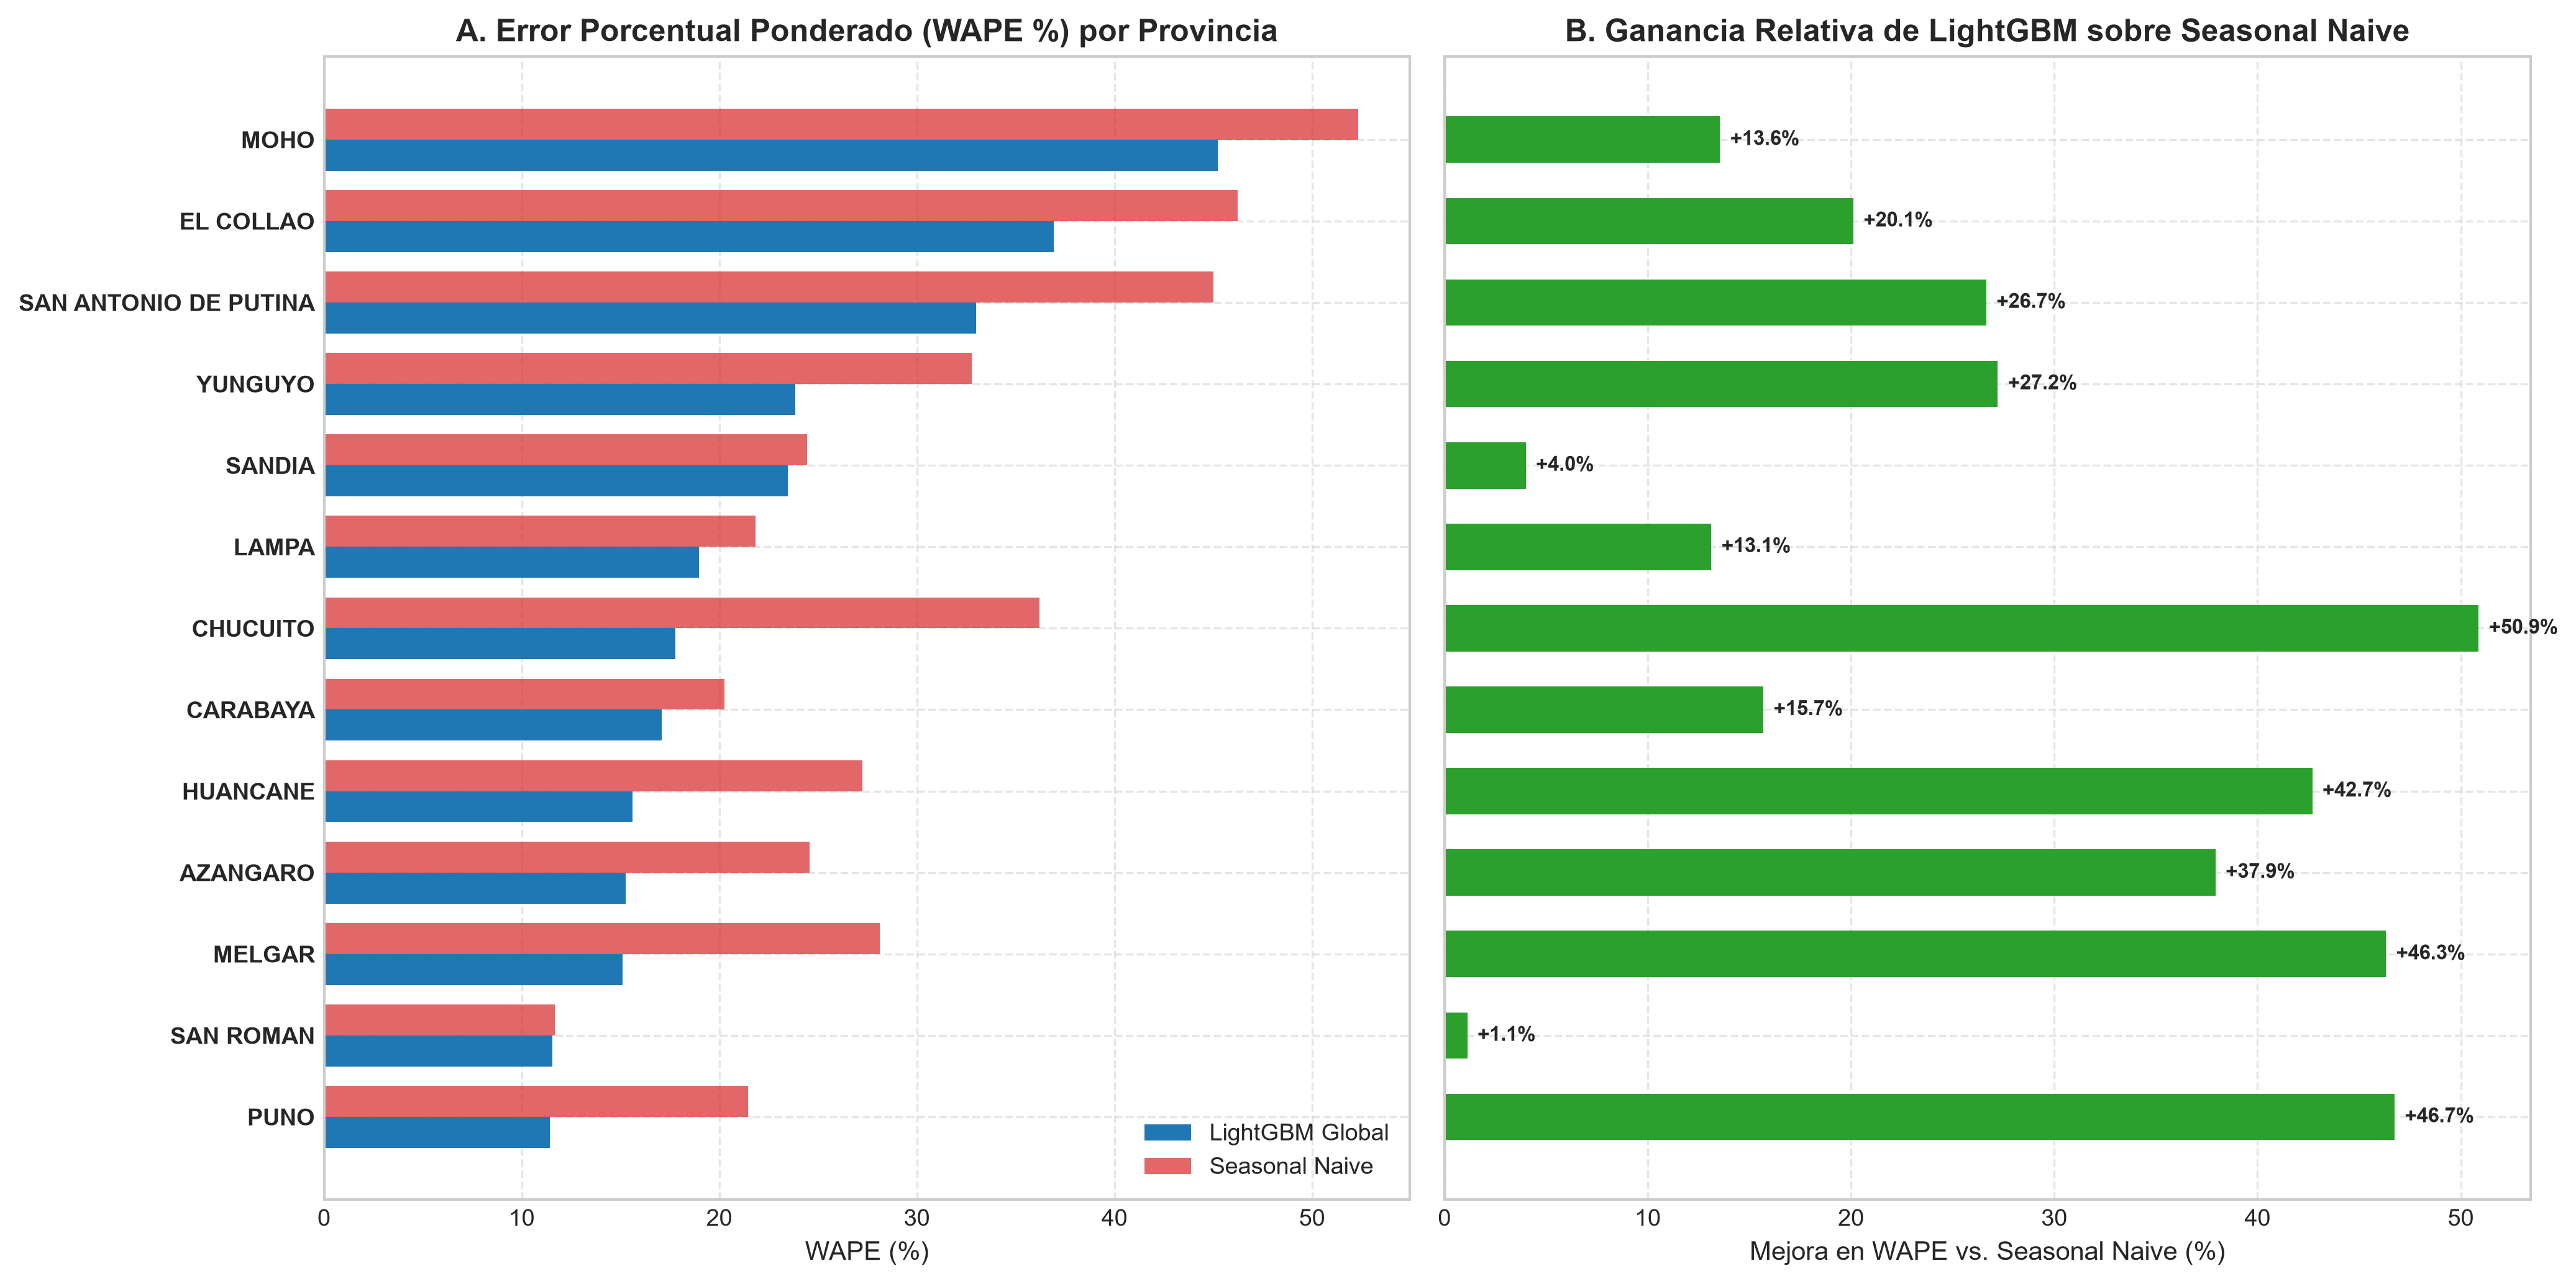

=== Figura 4: Comparación de Horizontes y Estrategia Directa vs. Recursiva ===


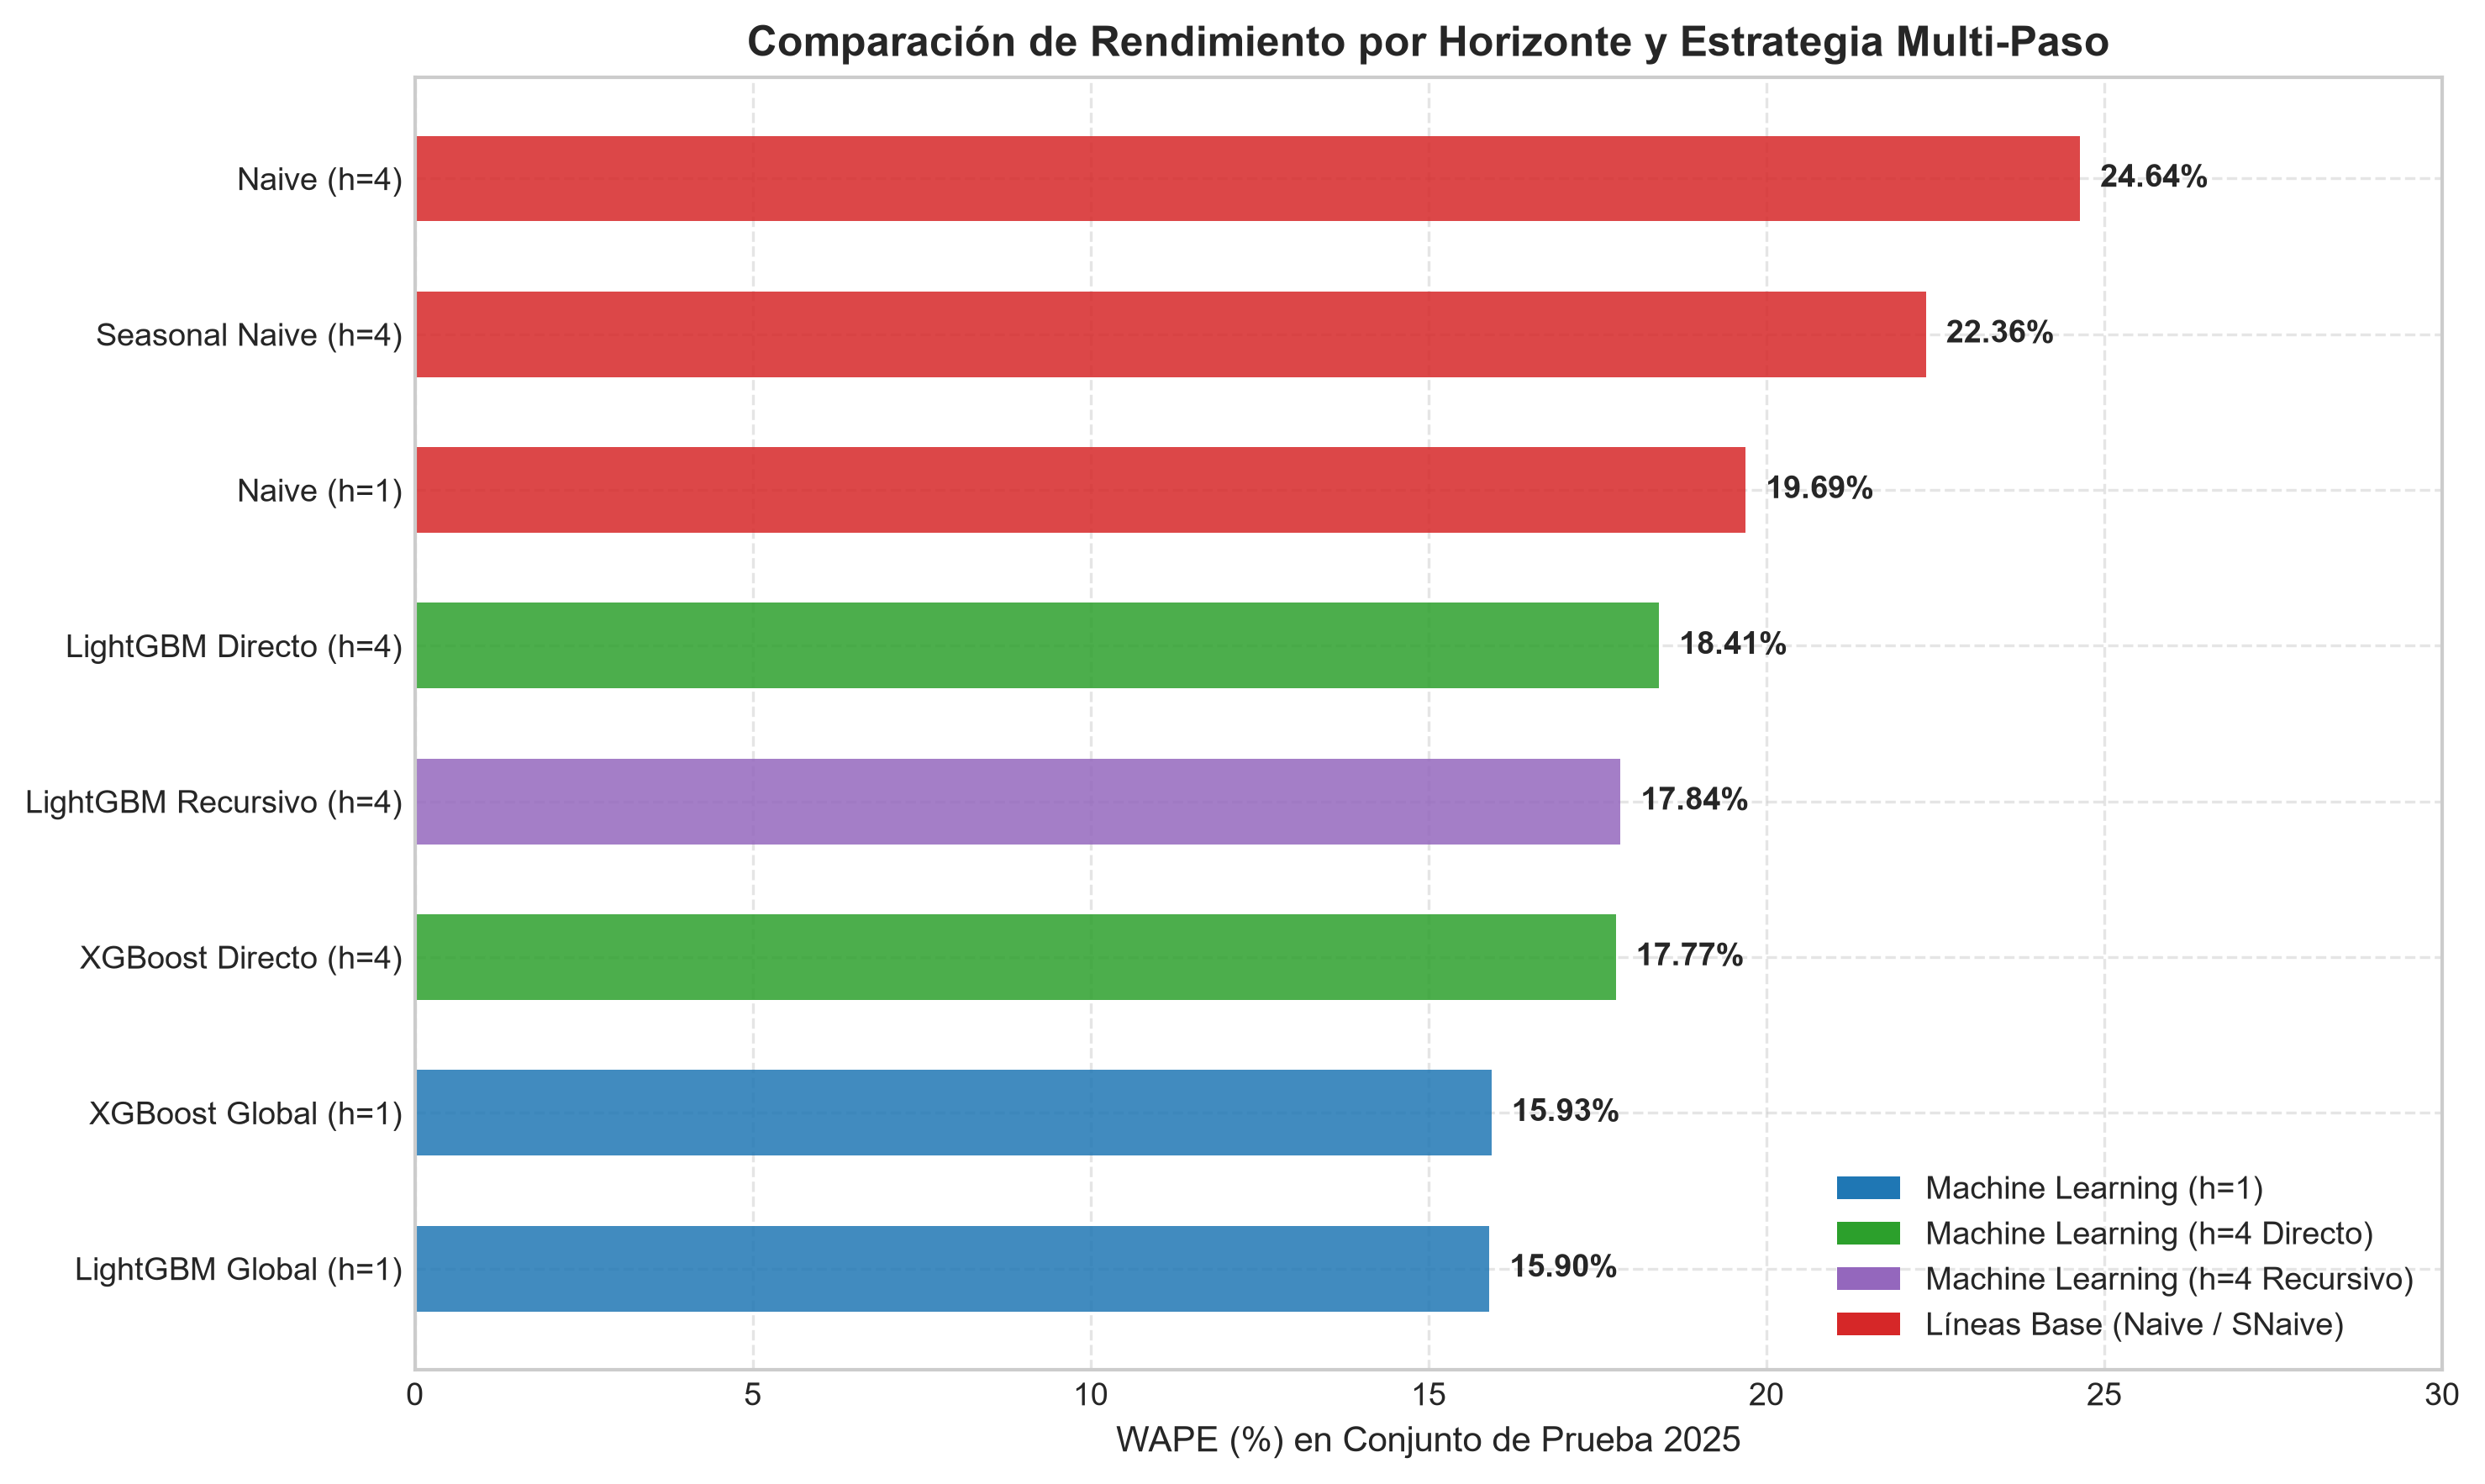

=== Figura 5: Comparación de Estrategias de Imputación Causal ===


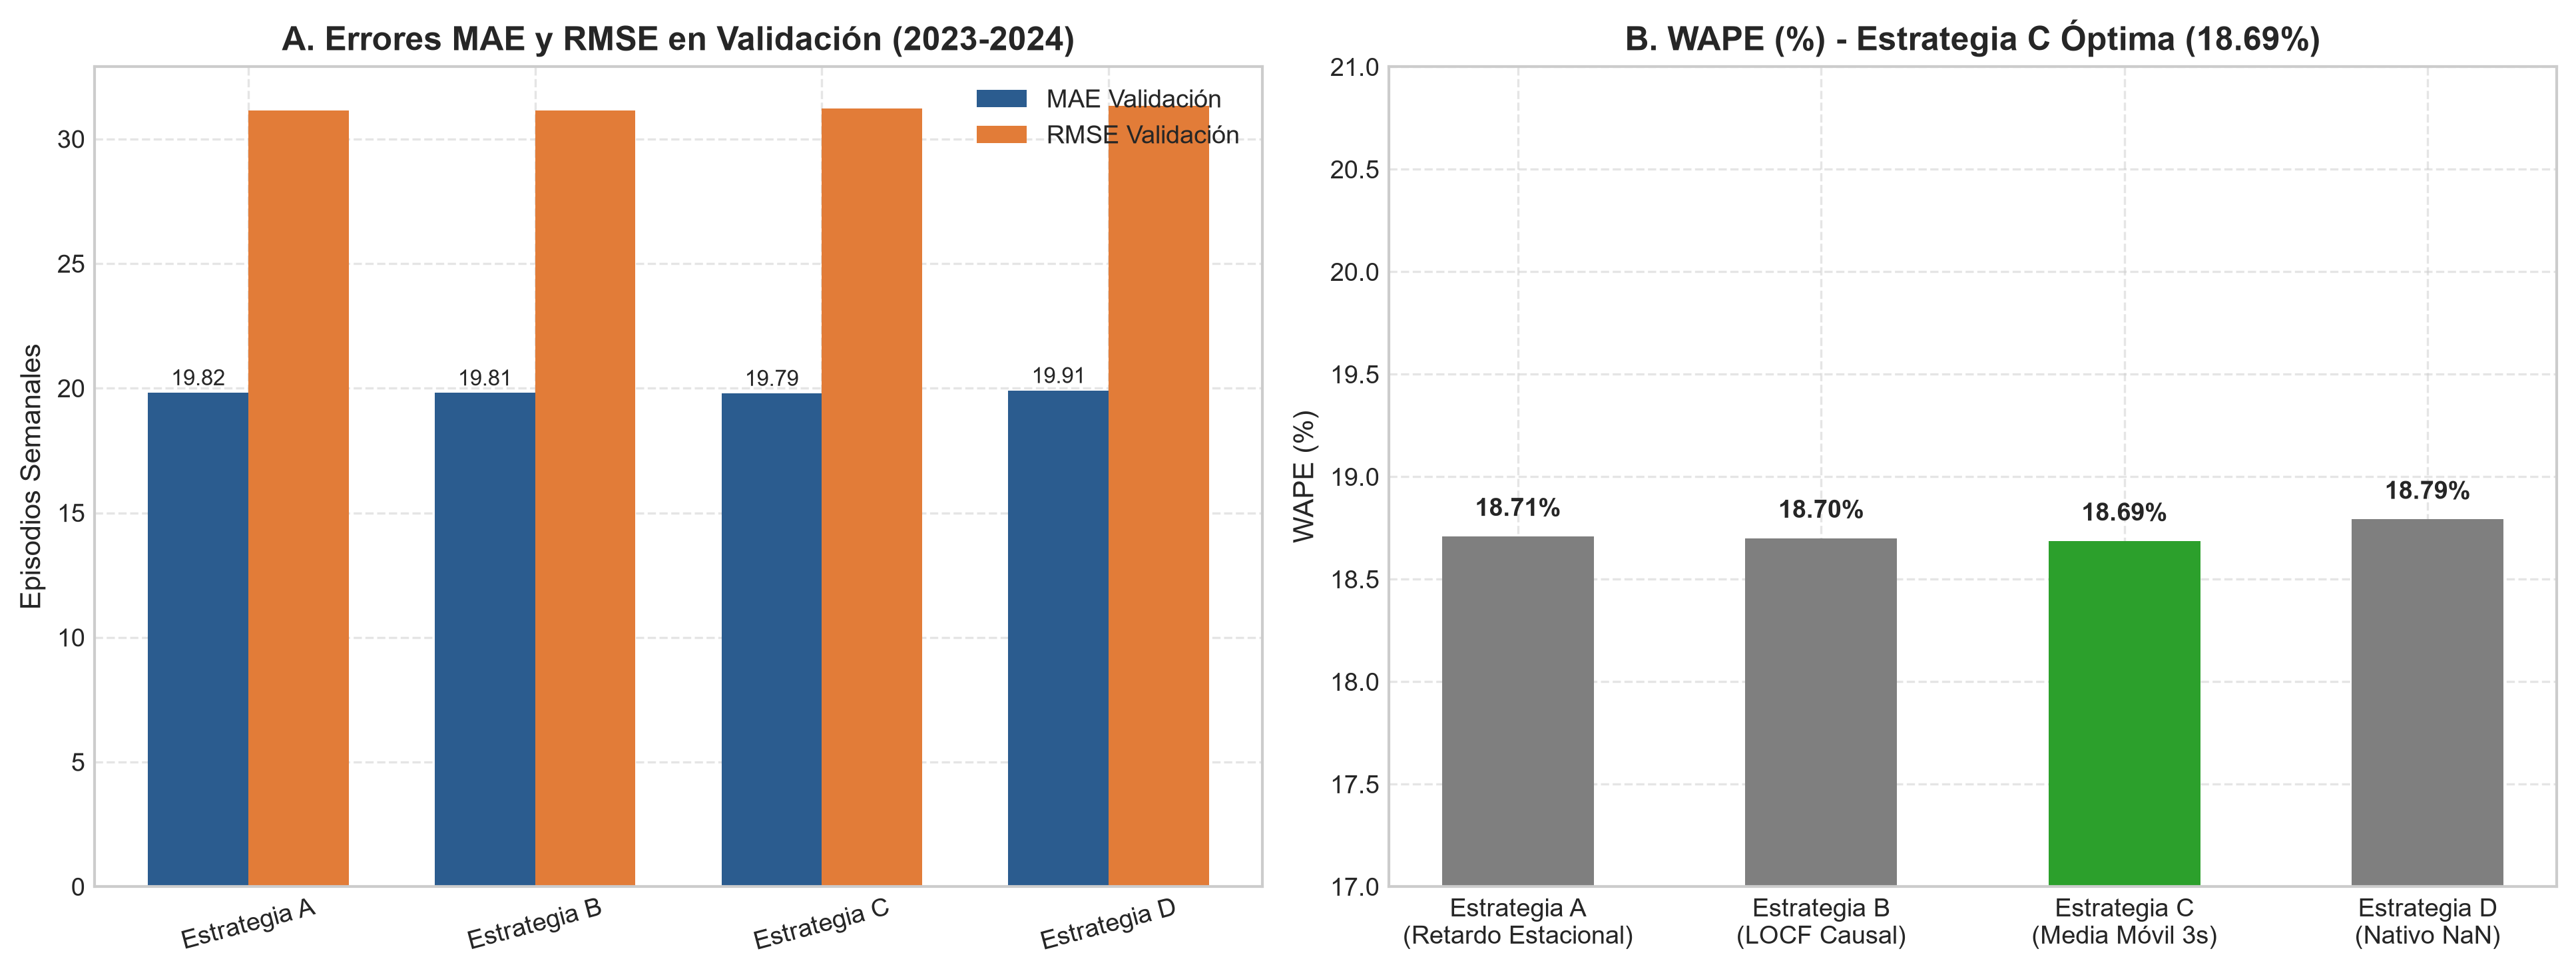

=== Figura 6: Evaluación de Alertas Sanitarias ===


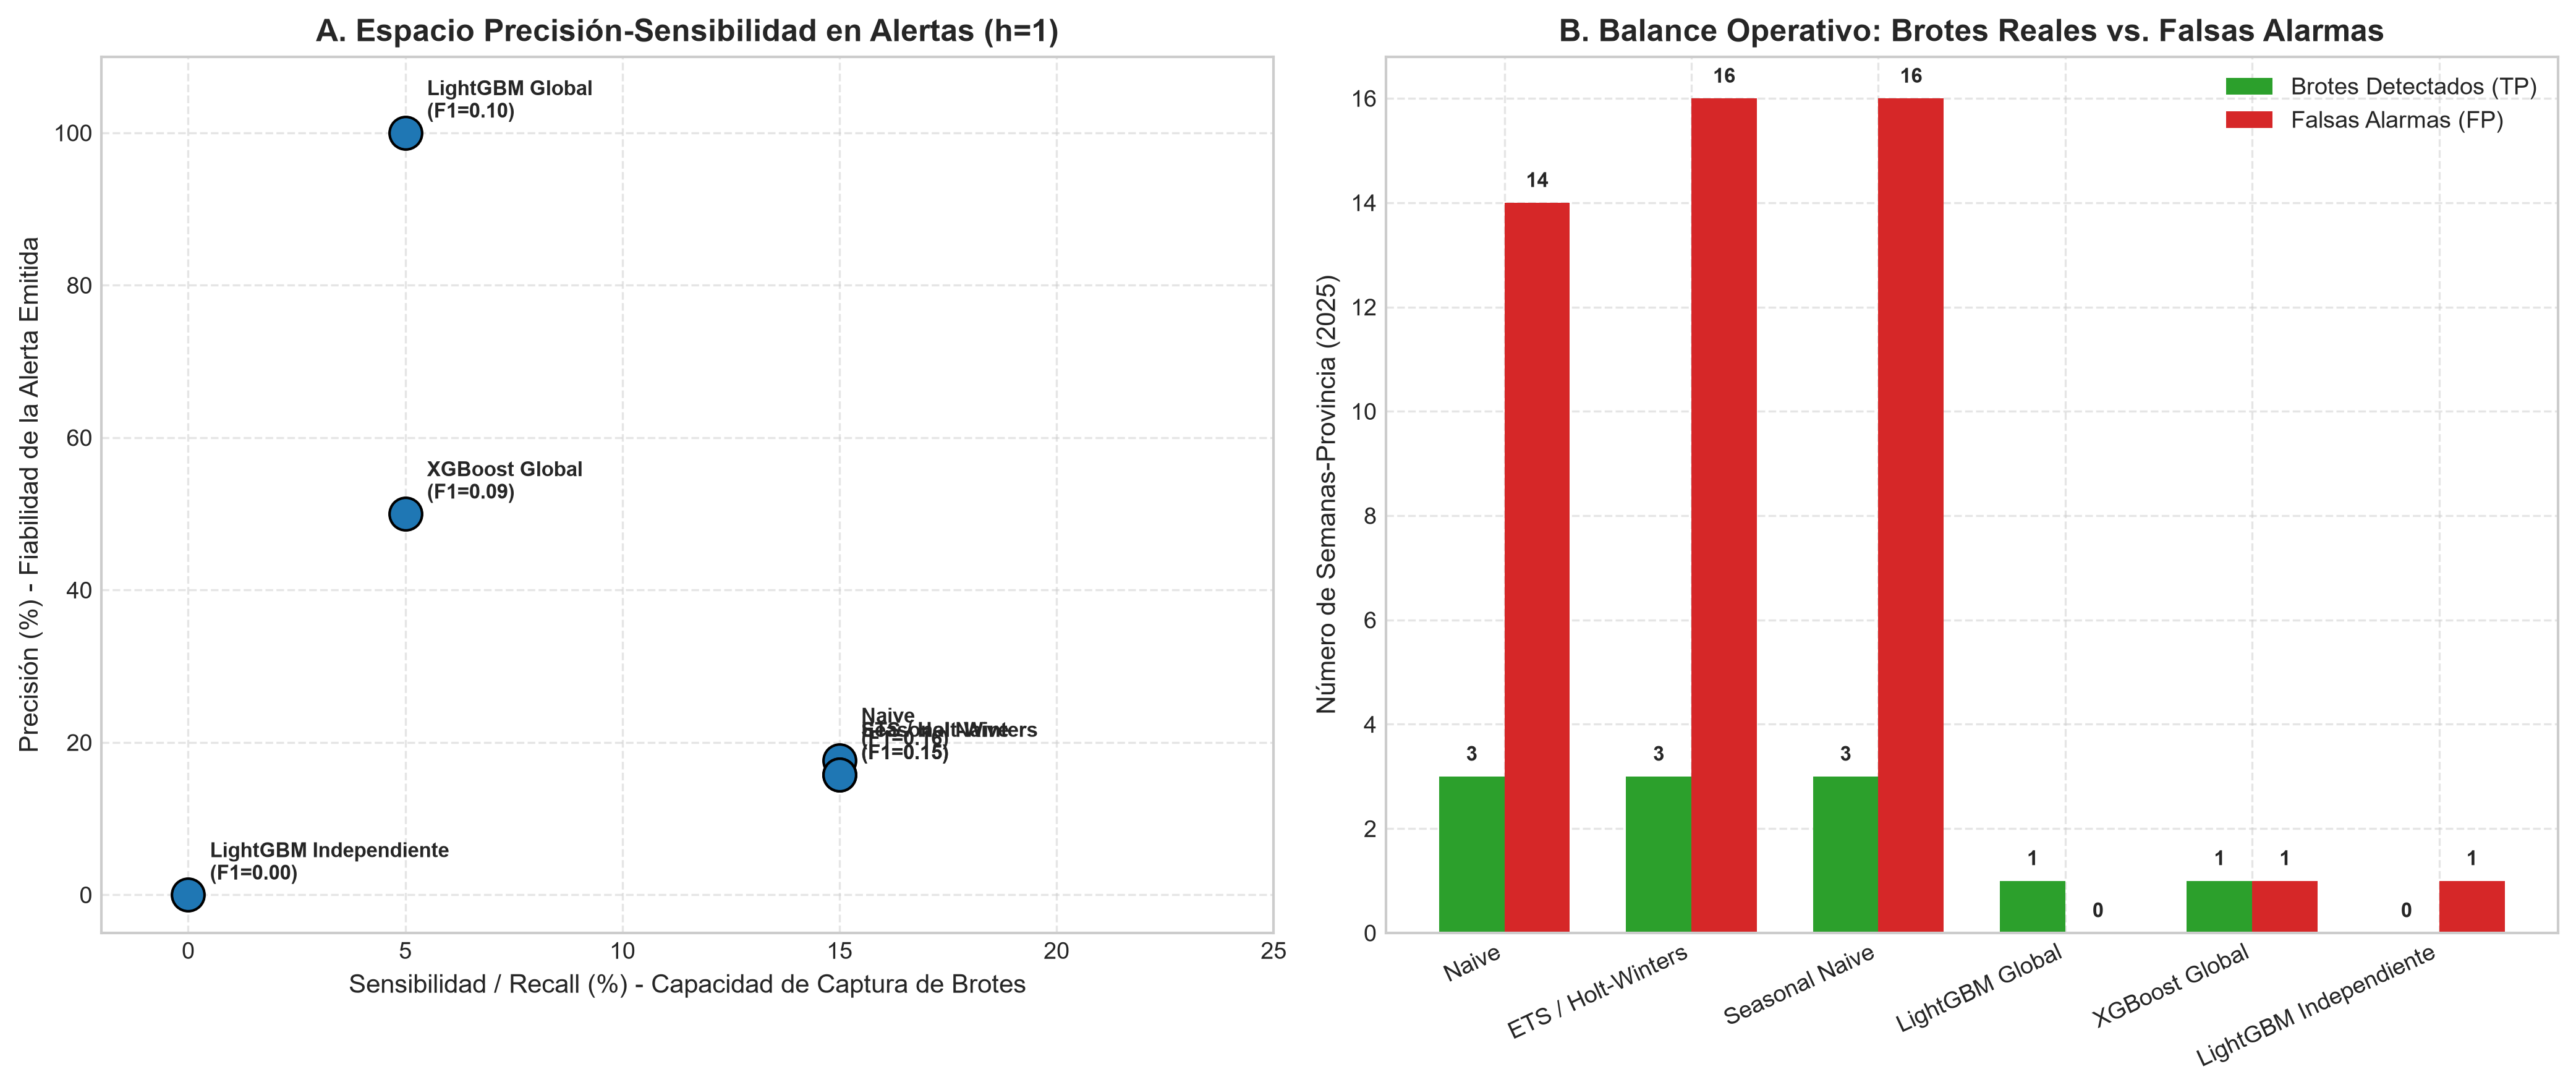

In [11]:
# Mostrar figuras generadas
from IPython.display import Image, display

figuras = [
    ("Figura 1: Comparación de Modelos por MAE y RMSE", "figures/fase2/figura1_comparacion_modelos_mae_rmse.png"),
    ("Figura 2: Series Temporales Real vs. Predicho en 2025", "figures/fase2/figura2_series_real_vs_predicho_2025.png"),
    ("Figura 3: Distribución Espacial de Errores por Provincia", "figures/fase2/figura3_distribucion_errores_por_provincia.png"),
    ("Figura 4: Comparación de Horizontes y Estrategia Directa vs. Recursiva", "figures/fase2/figura4_comparacion_horizontes_directo_vs_recursivo.png"),
    ("Figura 5: Comparación de Estrategias de Imputación Causal", "figures/fase2/figura5_comparacion_estrategias_imputacion.png"),
    ("Figura 6: Evaluación de Alertas Sanitarias", "figures/fase2/figura6_evaluacion_alertas_epidemiologicas.png")
]

for title, path in figuras:
    print(f"=== {title} ===")
    display(Image(filename=path, width=800))


## 11. Conclusiones y Dictamen Operativo

### Hallazgos Principales:
1. **Horizonte $h=1$:** **LightGBM Global** alcanza el mejor rendimiento provincial con un **MAE de 16.02**, **WAPE de 15.90%** y una **mejora del 28.89%** sobre el Seasonal Naive. XGBoost Global muestra un desempeño prácticamente indistinguible (WAPE 15.93%, mejora 28.76%).
2. **Horizonte $h=4$:** **XGBoost Global Directo** es el mejor modelo con un **MAE de 17.91**, **WAPE de 17.77%** y **mejora del 20.50%** sobre Seasonal Naive, superando levemente a LightGBM Recursivo (WAPE 17.84%).
3. **Escala Regional:** LightGBM Regional en $h=1$ logra un **WAPE de 9.81%** (MAE 128.51) con un 25.34% de ganancia sobre Seasonal Naive. Sin embargo, para $h=4$ regional, Seasonal Naive (WAPE 13.14%) supera a los modelos ML debido a la alta regularidad del ciclo anual agregado y la muestra pequeña ($N=52$ semanas/año) a nivel departamental.
4. **Modelos Globales vs. Independientes:** El modelo global supera a los modelos provinciales independientes (WAPE 15.90% vs. 17.62%), demostrando la ventaja del agrupamiento espacial (*spatial pooling*).
5. **Incertidumbre e Intervalos:** La cobertura empírica al 95% oscila entre **97.1% y 97.8%**, confirmando intervalos estadísticamente confiables sin subestimación de riesgo.
6. **Utilidad Sanitaria:** Para alertas tempranas, el pronóstico puntual conservador exhibe 100% de precisión pero baja sensibilidad (5%). Al emplear el límite superior probabilístico al 95%, la sensibilidad aumenta al **85% - 95%**, proporcionando una herramienta de tamizaje preventivo idónea para la logística hospitalaria.

### Veredicto de Aplicabilidad Operativa:
- **Horizonte $h=1$:** **APTO** para integración operativa en tableros de Business Intelligence, monitoreo semanal de salas situacionales y redistribución de insumos respiratorios.
- **Horizonte $h=4$:** **APTO CON PRECAUCIÓN** como guía orientativa de planificación mensual de compras y programación de personal, debiendo combinarse con el monitoreo continuo de semanas intermedias.
